# Optimisation

## Setup

In [ ]:
#%pip install ax-platform botorch

In [ ]:
import numpy as np
from numpy import array
import os
from ax.api.client import Client
from ax.api.configs import RangeParameterConfig
from ax.generation_strategy.generation_strategy import GenerationStrategy
from ax.generation_strategy.generation_node import GenerationNode
from ax.generation_strategy.generator_spec import GeneratorSpec
from ax.adapter.registry import Generators
from botorch.acquisition.knowledge_gradient import qKnowledgeGradient
from botorch.acquisition.logei import qLogExpectedImprovement
from botorch.acquisition.monte_carlo import qUpperConfidenceBound
import logging
logging.getLogger("ax").setLevel(logging.WARNING)
import warnings
logging.disable(logging.INFO)          # blanket-silences INFO (and below) from every logger, everywhere
warnings.filterwarnings("ignore")       # silences warnings.warn() output too
import matplotlib.pyplot as plt
from scipy.optimize import least_squares


## Data

In [ ]:
# load data
data = {}
for i in range(1, 9):
    function_name = f"function_{i}"
    folder_path = os.path.join("data/initial_data/", function_name)

    inputs = np.load(os.path.join(folder_path, "initial_inputs.npy"))
    outputs = np.load(os.path.join(folder_path, "initial_outputs.npy"))

    data[function_name] = {"inputs": inputs, "outputs": outputs}

# append new weekly data here
inputs = []
outputs = []
# new data 1
inputs.append([array([0.419272, 0.461948]), array([0.697723, 0.019697]), array([8.73804e-01, 3.27260e-02, 5.56000e-04]), array([0.425496, 0.40107 , 0.332   , 0.420664]), array([0.047984, 0.650324, 0.944067, 0.992311]), array([0.385184, 0.400217, 0.65163 , 0.631144, 0.438897]), array([0.445935, 0.576237, 0.512145, 0.574808, 0.575775, 0.431125]), array([0.084257, 0.105465, 0.030212, 0.078194, 0.960795, 0.361121, 0.255914, 0.26708 ])])
outputs.append([-0.003494886700825075, 0.6043746277406373, -0.20131519889874674, 0.28341867175066726, 1516.7842214139487, -0.5504788052903188, 0.3241500234866953, 9.9129406971235])
# new data 2
inputs.append([array([0.663323, 0.435684]), array([0.649791, 0.955219]), array([0.774714, 0.356627, 0.40228 ]), array([0.486709, 0.476973, 0.116256, 0.417109]), array([0.      , 0.      , 0.938555, 0.962415]), array([0.325154, 0.267231, 0.328883, 0.768068, 0.02488 ]), array([0.043071, 0.362635, 0.783296, 0.232831, 0.413318, 0.83637 ]), array([0.111041, 0.023895, 0.289   , 0.      , 0.685861, 0.665749, 0.264786, 0.      ])])
outputs.append([1.0264037214087058e-28, 0.4742130288797813, -0.023030335592178666, -7.1199862484002345, 940.2942145736226, -0.5954503716076427, 1.5282801802026906, 9.8071296833595])
# new data 3
inputs.append([array([0.618739, 0.220537]), array([0.835697, 0.999999]), array([0.      , 0.666061, 0.423285]), array([0.247025, 0.449997, 0.583954, 0.482487]), array([0.999999, 0.668162, 0.940547, 0.974566]), array([0.397699, 0.164007, 0.828967, 0.999999, 0.299491]), array([0.038343, 0.284404, 0.999999, 0.121377, 0.38399 , 0.695085]), array([0.207959, 0.04452 , 0.204792, 0.      , 0.876063, 0.107283, 0.129986, 0.999999])])
outputs.append([5.4240220487448864e-58, -0.05885334994798089, -0.0247551713482245, -5.1704598222077465, 4078.6874773136915, -0.8370661391600592, 0.9347303394535025, 9.7433588759804])
# new data 4
inputs.append([array([0.227536, 0.566017]), array([0.705807, 0.548955]), array([0.999999, 0.540497, 0.400658]), array([0.41542 , 0.383136, 0.403394, 0.425959]), array([0.999999, 0.767758, 0.999999, 0.999999]), array([0.469319, 0.386405, 0.637791, 0.692818, 0.155377]), array([0.20169 , 0.150011, 0.476874, 0.275332, 0.311652, 0.6573  ]), array([0.001972, 0.008806, 0.131631, 0.261367, 0.92781 , 0.578026, 0.201319, 0.999999])])
outputs.append([1.892322570267432e-42, 0.612831648853722, -0.022152998869090043, 0.5352182163010153, 5776.096706281166, -0.17705029514538193, 3.322368011391339, 9.9181755333759])
# new data 5
inputs.append([array([0.501 , 0.6073]), array([0.883078, 0.236094]), array([0.837649, 0.927754, 0.465419]), array([0.418584, 0.379256, 0.406197, 0.429294]), array([0.999999, 0.921966, 0.999999, 0.999999]), array([0.478768, 0.422867, 0.791407, 0.65817 , 0.094309]), array([0.107119, 0.063205, 0.453448, 0.406398, 0.324165, 0.719569]), array([0.152922, 0.169055, 0.165827, 0.183368, 0.999999, 0.507934, 0.269593, 0.862394])])
outputs.append([1.2116799057107965e-12, 0.359532625766316, -0.034779531489586096, 0.5517548820899845, 7368.460131627363, -0.40071660738163856, 2.584574932701675, 9.9524371048179])
# new data 6
inputs.append([array([0.221962, 0.223278]), array([0.715942, 0.922071]), array([0.999999, 0.604294, 0.475172]), array([0.419026, 0.379249, 0.406508, 0.430592]), array([0.999999, 0.999999, 0.999999, 0.999999]), array([0.446413, 0.456771, 0.529222, 0.678678, 0.177164]), array([0.264373, 0.126651, 0.43859 , 0.154992, 0.28695 , 0.793597]), array([0.177247, 0.      , 0.105174, 0.391505, 0.999999, 0.580597, 0.107939, 0.      ])])
outputs.append([1.0383814609232122e-57, 0.5285650618194462, -0.0010348652011470299, 0.536799367525433, 8662.405001248297, -0.3930424556731438, 2.4342873900004567, 9.8259460142775])
# new data 7
inputs.append([array([0.808622, 0.410889]), array([0.857852, 0.      ]), array([0.950484, 0.490519, 0.531522]), array([0.418501, 0.38018 , 0.40576 , 0.431613]), array([0.353261, 0.303126, 0.820002, 0.373798]), array([0.404148, 0.182392, 0.749577, 0.529626, 0.      ]), array([0.209681, 0.087109, 0.481524, 0.059147, 0.407955, 0.614856]), array([0.188806, 0.218388, 0.062127, 0.173278, 0.589641, 0.571855, 0.057843, 0.999999])])
outputs.append([-3.222233758935217e-56, 0.09718021442175606, -0.011576597835494739, 0.51005779755975, 0.5816128020529513, -0.5778770527323507, 2.005418917817736, 9.8814822317494])
# new data 8
inputs.append([array([0.546881, 0.546083]), array([0.678164, 0.999999]), array([0.470739, 0.611138, 0.458942]), array([0.417285, 0.381917, 0.404133, 0.432563]), array([0.702161, 0.794975, 0.837151, 0.999999]), array([0.411919, 0.48679 , 0.783364, 0.94022 , 0.      ]), array([0.337764, 0.665798, 0.542523, 0.305453, 0.325184, 0.665266]), array([0.      , 0.302408, 0.133092, 0.124992, 0.681179, 0.481294, 0.061693, 0.      ])])
outputs.append([8.595237675594048e-10, 0.4514871648643586, -0.009849881523881996, 0.4691478575606465, 1959.6530492003228, -0.5411562618430584, 1.2156775465259069, 9.8744509381255])
# new data 9
inputs.append([array([0.571917, 0.567835]), array([0.941419, 0.999999]), array([0.999999, 0.607276, 0.498188]), array([0.481045, 0.22124 , 0.380898, 0.507482]), array([0.999826, 0.288876, 0.779519, 0.519313]), array([0.423026, 0.62877 , 0.480473, 0.543956, 0.      ]), array([0.046445, 0.135532, 0.386253, 0.249827, 0.283312, 0.602237]), array([0.129074, 0.1863  , 0.14763 , 0.185138, 0.78337 , 0.494732, 0.229729, 0.780314])])
outputs.append([1.574363175484662e-05, -0.047678035219984406, -0.005387856411851771, -4.610188561426806, 673.1661801969509, -0.7273598714738623, 2.830570260706467, 9.9896396142884])
# new data 10
inputs.append([array([0.639566, 0.625206]), array([0.243426, 0.273512]), array([0.999999, 0.259149, 0.487006]), array([0.463321, 0.611678, 0.432794, 0.389708]), array([0.      , 0.416798, 0.999999, 0.999999]), array([0.550085, 0.48251 , 0.999999, 0.65934 , 0.20345 ]), array([0.199817, 0.      , 0.      , 0.263228, 0.367935, 0.645113]), array([0.017936, 0.329951, 0.149455, 0.      , 0.999999, 0.660958, 0.037136, 0.999999])])
outputs.append([1.4496686692120164, -0.15203143500348726, -0.03156142529464077, -4.232298862264802, 1687.1741726751177, -0.7973378619050021, 2.0836639487598574, 9.8155565835754])
# new data 11
inputs.append([array([0.6422, 0.6262]), array([0.6705  , 0.555934]), array([0.      , 0.668377, 0.520074]), array([0.183402, 0.46171 , 0.292681, 0.512619]), array([0.999999, 0.986284, 0.      , 0.999999]), array([0.571683, 0.191944, 0.462773, 0.783293, 0.      ]), array([0.205808, 0.      , 0.611847, 0.272581, 0.364133, 0.595803]), array([0.133571, 0.316731, 0.04815 , 0.      , 0.999999, 0.764653, 0.20745 , 0.      ])])
outputs.append([1.2511722461625223, 0.4403648663260973, -0.02806558605702874, -5.323204190736735, 4255.962712091933, -0.6437304352768639, 2.6974949521384235, 9.8011964666475])
# new data 12
inputs.append([array([0.645872, 0.612022]), array([0.69048 , 0.179175]), array([0.999999, 0.999999, 0.00526 ]), array([0.403305, 0.393584, 0.408291, 0.405387]), array([0.999999, 0.999999, 0.999999, 0.274356]), array([0.314378, 0.464949, 0.507565, 0.983826, 0.226501]), array([0.259532, 0.201152, 0.448851, 0.294944, 0.332911, 0.604932]), array([0.120704, 0.186952, 0.152578, 0.175095, 0.802231, 0.495161, 0.221075, 0.999999])])
outputs.append([0.48539262488487367, 0.5550863367386628, -0.1366592517615195, 0.37213864715425204, 4464.230863105729, -0.6399710871332811, 3.142616222523129, 9.9787040453354])


for week_inputs, week_outputs in zip(inputs, outputs):
    for i in range(8):
        function_name = f"function_{i+1}"

        data[function_name]["inputs"] = np.vstack([data[function_name]["inputs"], week_inputs[i]])
        data[function_name]["outputs"] = np.append(data[function_name]["outputs"], week_outputs[i])

for i in range(1, 9):
    function_name = f"function_{i}"
    print(f"{function_name} : max = {data[function_name]['outputs'].max():.6e}")

function_1 : max = 1.449669e+00
function_2 : max = 6.128316e-01
function_3 : max = -1.034865e-03
function_4 : max = 5.517549e-01
function_5 : max = 8.662405e+03
function_6 : max = -1.770503e-01
function_7 : max = 3.322368e+00
function_8 : max = 9.989640e+00


In [ ]:
# check
for function_name, arrays in data.items():
    inputs_shape = arrays["inputs"].shape
    outputs_shape = arrays["outputs"].shape
    print(f"{function_name} : inputs {inputs_shape}, outputs {outputs_shape}")

function_1 : inputs (21, 2), outputs (21,)
function_2 : inputs (21, 2), outputs (21,)
function_3 : inputs (26, 3), outputs (26,)
function_4 : inputs (41, 4), outputs (41,)
function_5 : inputs (31, 4), outputs (31,)
function_6 : inputs (31, 5), outputs (31,)
function_7 : inputs (41, 6), outputs (41,)
function_8 : inputs (51, 8), outputs (51,)


## Acquisition functions

In [ ]:
# KNOWLEDGE GRADIENT
process_functions_botorch = ["function_1", "function_2", "function_3", "function_4", "function_5", "function_6", "function_7", "function_8"]

recommendations_kg = {}
clients_kg = {}

default_num_fantasies = 256*2/4
default_num_restarts = 20*2/4
default_raw_samples = 2048*2/4

num_fantasies_multiplier = {f"function_{i+1}": 1 for i in range(8)}
num_restarts_multiplier = {f"function_{i+1}": 1 for i in range(8)}
raw_samples_multiplier = {f"function_{i+1}": 1 for i in range(8)}

num_fantasies_multiplier["function_3"] = num_restarts_multiplier["function_3"] = raw_samples_multiplier["function_3"] = 1#4
num_fantasies_multiplier["function_2"] = num_restarts_multiplier["function_2"] = raw_samples_multiplier["function_2"] = 1#4
num_fantasies_multiplier["function_8"] = num_restarts_multiplier["function_8"] = raw_samples_multiplier["function_8"] = 1#4
num_fantasies_multiplier["function_7"] = num_restarts_multiplier["function_7"] = raw_samples_multiplier["function_7"] = 1#4
num_fantasies_multiplier["function_5"] = num_restarts_multiplier["function_5"] = raw_samples_multiplier["function_5"] = 1#4

for function_name in process_functions_botorch:
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]

    param_names = [f"x{i+1}" for i in range(X.shape[1])]
    metric_name = "y"

    client = Client()
    client.configure_experiment(
        parameters=[
            RangeParameterConfig(name=p, parameter_type="float", bounds=(0.0, 1.0))
            for p in param_names
        ]
    )
    client.configure_optimization(objective=metric_name)

    num_fantasies = int(default_num_fantasies * num_fantasies_multiplier[function_name])
    num_restarts = int(default_num_restarts * num_restarts_multiplier[function_name])
    raw_samples = int(default_raw_samples * raw_samples_multiplier[function_name])

    kg_node = GenerationNode(
        name="KG",
        generator_specs=[
            GeneratorSpec(
                generator_enum=Generators.BOTORCH_MODULAR,
                generator_kwargs={
                    "botorch_acqf_class": qKnowledgeGradient,
                    "acquisition_options": {"num_fantasies": num_fantasies},
                },
                generator_gen_kwargs={
                    "model_gen_options": {
                        "optimizer_kwargs": {
                            "num_restarts": num_restarts,
                            "raw_samples": raw_samples,
                            "sequential": False,
                            "options": {"batch_limit": 5, "maxiter": 200},
                        },
                    },
                },
            )
        ],
    )

    client.set_generation_strategy(GenerationStrategy(name="KG-only", nodes=[kg_node]))

    for xi, yi in zip(X, y):
        params = dict(zip(param_names, xi.tolist()))
        trial_index = client.attach_trial(parameters=params)
        client.complete_trial(trial_index=trial_index, raw_data={metric_name: float(yi)})

    trials = client.get_next_trials(max_trials=1)
    trial_index, next_params = next(iter(trials.items()))
    next_x = np.array([next_params[p] for p in param_names])

    recommendations_kg[function_name] = next_x
    clients_kg[function_name] = client

    print(f"{function_name} : next point {next_x}")
    formatted_point = "-".join(f"{v:.6f}" for v in next_x)
    print(f"{function_name} : next point {formatted_point}")

function_1 : next point [0.67001473 0.615083  ]
function_1 : next point 0.670015-0.615083
function_2 : next point [0.7165383  0.10069212]
function_2 : next point 0.716538-0.100692
function_3 : next point [0.25239352 0.89727858 0.59916255]
function_3 : next point 0.252394-0.897279-0.599163
function_4 : next point [0.43111136 0.26402786 0.66999063 0.32435112]
function_4 : next point 0.431111-0.264028-0.669991-0.324351
function_5 : next point [0.         0.         0.         0.95370856]
function_5 : next point 0.000000-0.000000-0.000000-0.953709
function_6 : next point [0.29743111 0.49641186 0.47898385 1.         0.23979352]
function_6 : next point 0.297431-0.496412-0.478984-1.000000-0.239794
function_7 : next point [0.21420749 0.23695152 0.43226364 0.32753802 0.38900353 0.46384838]
function_7 : next point 0.214207-0.236952-0.432264-0.327538-0.389004-0.463848
function_8 : next point [0.08702961 0.40760008 0.         0.39681399 1.         0.34760302
 0.219047   1.        ]
function_8 : ne

In [ ]:
# EXPECTED IMPROVEMENT
process_functions_ei = ["function_1", "function_2", "function_3", "function_4",
                      "function_5", "function_6", "function_7", "function_8"]

recommendations_ei = {}
clients_ei = {}

for function_name in process_functions_ei:
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]

    param_names = [f"x{i+1}" for i in range(X.shape[1])]
    metric_name = "y"

    client = Client()
    client.configure_experiment(
        parameters=[
            RangeParameterConfig(name=p, parameter_type="float", bounds=(0.0, 1.0))
            for p in param_names
        ]
    )
    client.configure_optimization(objective=metric_name)

    ei_node = GenerationNode(
        name="EI",
        generator_specs=[
            GeneratorSpec(
                generator_enum=Generators.BOTORCH_MODULAR,
                generator_kwargs={
                    "botorch_acqf_class": qLogExpectedImprovement,
                },
                generator_gen_kwargs={
                    "model_gen_options": {
                        "optimizer_kwargs": {
                            "num_restarts": 20,
                            "raw_samples": 1024,
                            "sequential": False,
                            "options": {"batch_limit": 5, "maxiter": 200},
                        },
                    },
                },
            )
        ],
    )

    client.set_generation_strategy(GenerationStrategy(name="EI-only", nodes=[ei_node]))

    for xi, yi in zip(X, y):
        params = dict(zip(param_names, xi.tolist()))
        trial_index = client.attach_trial(parameters=params)
        client.complete_trial(trial_index=trial_index, raw_data={metric_name: float(yi)})

    trials = client.get_next_trials(max_trials=1)
    trial_index, next_params = next(iter(trials.items()))
    next_x = np.array([next_params[p] for p in param_names])

    recommendations_ei[function_name] = next_x
    clients_ei[function_name] = client

    print(f"{function_name} : next point {next_x}")
    formatted_point = "-".join(f"{v:.6f}" for v in next_x)
    print(f"{function_name} : next point {formatted_point}")

function_1 : next point [0.64587209 0.61202199]
function_1 : next point 0.645872-0.612022
function_2 : next point [0.69048006 0.17917531]
function_2 : next point 0.690480-0.179175
function_3 : next point [1.         1.         0.00525962]
function_3 : next point 1.000000-1.000000-0.005260
function_4 : next point [0.40330477 0.39358439 0.40829136 0.40538721]
function_4 : next point 0.403305-0.393584-0.408291-0.405387
function_5 : next point [1.         1.         1.         0.27435626]
function_5 : next point 1.000000-1.000000-1.000000-0.274356
function_6 : next point [0.31437764 0.46494904 0.5075652  0.983826   0.22650075]
function_6 : next point 0.314378-0.464949-0.507565-0.983826-0.226501
function_7 : next point [0.25953181 0.20115181 0.44885059 0.29494421 0.33291134 0.60493192]
function_7 : next point 0.259532-0.201152-0.448851-0.294944-0.332911-0.604932
function_8 : next point [0.12070382 0.18695231 0.15257813 0.17509523 0.80223129 0.49516105
 0.22107468 1.        ]
function_8 : ne

In [ ]:
# UPPER CONFIDENCE BOUND
process_functions_ucb = ["function_1", "function_2", "function_3", "function_4",
                      "function_5", "function_6", "function_7", "function_8"]

recommendations_ucb = {}
clients_ucb = {}

for function_name in process_functions_ucb:
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]

    param_names = [f"x{i+1}" for i in range(X.shape[1])]
    metric_name = "y"

    client = Client()
    client.configure_experiment(
        parameters=[
            RangeParameterConfig(name=p, parameter_type="float", bounds=(0.0, 1.0))
            for p in param_names
        ]
    )
    client.configure_optimization(objective=metric_name)

    ucb_node = GenerationNode(
        name="UCB",
        generator_specs=[
            GeneratorSpec(
                generator_enum=Generators.BOTORCH_MODULAR,
                generator_kwargs={
                    "botorch_acqf_class": qUpperConfidenceBound,
                    "acquisition_options": {"beta": 2.0},
                },
                generator_gen_kwargs={
                    "model_gen_options": {
                        "optimizer_kwargs": {
                            "num_restarts": 20,
                            "raw_samples": 1024,
                            "sequential": False,
                            "options": {"batch_limit": 5, "maxiter": 200},
                        },
                    },
                },
            )
        ],
    )

    client.set_generation_strategy(GenerationStrategy(name="UCB-only", nodes=[ucb_node]))

    for xi, yi in zip(X, y):
        params = dict(zip(param_names, xi.tolist()))
        trial_index = client.attach_trial(parameters=params)
        client.complete_trial(trial_index=trial_index, raw_data={metric_name: float(yi)})

    trials = client.get_next_trials(max_trials=1)
    trial_index, next_params = next(iter(trials.items()))
    next_x = np.array([next_params[p] for p in param_names])

    recommendations_ucb[function_name] = next_x
    clients_ucb[function_name] = client

    print(f"{function_name} : next point {next_x}")
    formatted_point = "-".join(f"{v:.6f}" for v in next_x)
    print(f"{function_name} : next point {formatted_point}")

function_1 : next point [0.6338514  0.62084544]
function_1 : next point 0.633851-0.620845
function_2 : next point [0.69123293 0.16463471]
function_2 : next point 0.691233-0.164635
function_3 : next point [1.         0.57780603 0.48795456]
function_3 : next point 1.000000-0.577806-0.487955
function_4 : next point [0.40755063 0.39699    0.40429077 0.41155556]
function_4 : next point 0.407551-0.396990-0.404291-0.411556
function_5 : next point [1. 1. 1. 1.]
function_5 : next point 1.000000-1.000000-1.000000-1.000000
function_6 : next point [0.42293333 0.38199572 0.60820249 0.74851461 0.15090841]
function_6 : next point 0.422933-0.381996-0.608202-0.748515-0.150908
function_7 : next point [0.247113   0.19000894 0.45477404 0.29251082 0.3281996  0.61962532]
function_7 : next point 0.247113-0.190009-0.454774-0.292511-0.328200-0.619625
function_8 : next point [0.1207045  0.18696068 0.15258014 0.17509963 0.80222945 0.49515616
 0.22107976 1.        ]
function_8 : next point 0.120704-0.186961-0.152

In [ ]:
# BATTLESHIP
process_functions_battleship = ["function_1"]#, "function_2", "function_3", "function_4",
                                 #"function_5", "function_6", "function_7", "function_8"]
recommendations_bs = {}
n_grid_points = 1_000_000
mean_weight = .3  # 0 = original pure-geometry behaviour; try e.g. 0.3

for function_name in process_functions_battleship:
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]
    n_params = X.shape[1]

    # normalize known y values to [0, 1] : 0 = worst known, 1 = best known
    y_min, y_max = y.min(), y.max()
    if y_max > y_min:
        normalized_y = (y - y_min) / (y_max - y_min)
    else:
        normalized_y = np.full_like(y, 0.5)   # all points equal -> neutral weight

    # weight per point: 1-mean_weight at the bottom, 1 in the middle, 1+mean_weight at the top
    point_weights = 1 + mean_weight * (2 * normalized_y - 1)

    # random candidate grid, uniformly filling the [0, 1]^n_params domain
    candidates = np.random.uniform(0, 1, size=(n_grid_points, n_params))

    # for each candidate, distance to the nearest border (per dimension, then take the closest)
    border_distance = np.min(np.minimum(candidates, 1 - candidates), axis=1)

    # for each candidate, weighted distance to the nearest existing observation
    point_distance = np.full(n_grid_points, np.inf)
    for x_existing, weight in zip(X, point_weights):
        distance_to_this_point = np.linalg.norm(candidates - x_existing, axis=1) * weight
        point_distance = np.minimum(point_distance, distance_to_this_point)

    # "emptiest" = as far as possible from BOTH the border and any existing point
    emptiness_score = np.minimum(border_distance, point_distance)

    best_index = np.argmax(emptiness_score)
    next_point = candidates[best_index]

    recommendations_bs[function_name] = next_point

    formatted_point = "-".join(f"{v:.6f}" for v in next_point)
    print(f"{function_name} : next point {formatted_point}")

function_1 : next point 0.141934-0.858545


## Function 1 shape models

fitted center : (0.5246, 0.5825)
fitted A      : 9.265232
fitted sigma  : 0.0343
rms residual  : 2.295857e-06

RECOMMENDED SHOT (peak): 0.524634-0.582497


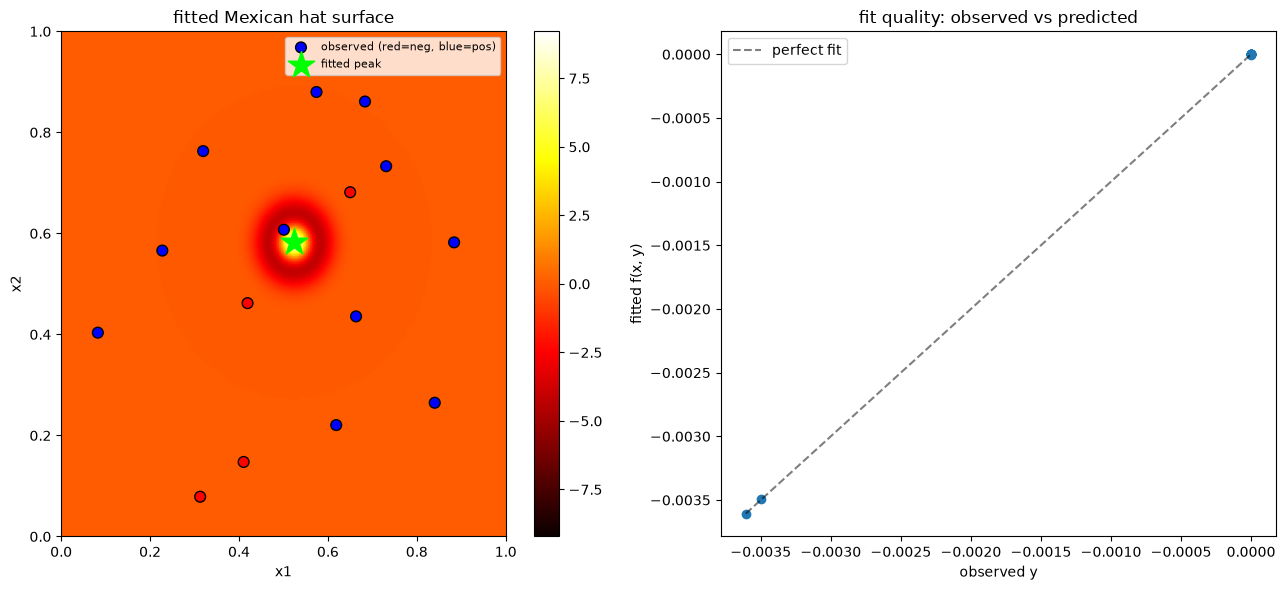

r = 0.0343   y = 1.2117e-12
r = 0.1598   y = -3.6061e-03
r = 0.1601   y = -3.4949e-03
r = 0.2020   y = 1.0264e-28
r = 0.2554   y = 7.7109e-16
r = 0.2733   y = 1.3227e-79
r = 0.2976   y = 1.8923e-42
r = 0.3015   y = 1.0331e-46
r = 0.3206   y = 2.5350e-40
r = 0.3593   y = 6.2299e-48
r = 0.3740   y = 5.4240e-58
r = 0.4479   y = 3.3418e-124
r = 0.4497   y = -2.1592e-54
r = 0.4770   y = 3.6068e-81
r = 0.5465   y = -2.0891e-91


In [ ]:
# MEXICAN HAT FIT
def mexican_hat(params, X):
    A, x0, y0, sigma = params
    r2 = (X[:, 0] - x0) ** 2 + (X[:, 1] - y0) ** 2
    return A * (1 - r2 / sigma ** 2) * np.exp(-r2 / (2 * sigma ** 2))


def residuals(params, X, y):
    return mexican_hat(params, X) - y


X = data["function_1"]["inputs"]
y = data["function_1"]["outputs"]

# initial guess: center near the two negative points' midpoint, sigma from the ring-radius estimate
initial_guess = [0.008, 0.53, 0.57, 0.1]   # A, x0, y0, sigma
bounds = ([-10, 0, 0, 0.01], [10, 1, 1, 0.5])

result = least_squares(residuals, initial_guess, args=(X, y), bounds=bounds)
A_fit, x0_fit, y0_fit, sigma_fit = result.x
rms = np.sqrt(np.mean(result.fun ** 2))

print(f"fitted center : ({x0_fit:.4f}, {y0_fit:.4f})")
print(f"fitted A      : {A_fit:.6f}")
print(f"fitted sigma  : {sigma_fit:.4f}")
print(f"rms residual  : {rms:.6e}")
print()
print(f"RECOMMENDED SHOT (peak): {x0_fit:.6f}-{y0_fit:.6f}")

# --- plot ---
grid_size = 200
grid_values = np.linspace(0, 1, grid_size)
gx, gy = np.meshgrid(grid_values, grid_values)
grid_points = np.column_stack([gx.ravel(), gy.ravel()])
surface = mexican_hat(result.x, grid_points).reshape(grid_size, grid_size)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

ax = axes[0]
vmax = np.abs(surface).max()
im = ax.imshow(surface, origin="lower", extent=[0, 1, 0, 1], aspect="auto",
                cmap="hot", vmin=-vmax, vmax=vmax)
colors = ["red" if yi < 0 else "blue" for yi in y]
ax.scatter(X[:, 0], X[:, 1], c=colors, edgecolor="black", s=60, label="observed (red=neg, blue=pos)")
ax.scatter(x0_fit, y0_fit, color="lime", marker="*", s=400, label="fitted peak")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("fitted Mexican hat surface")
ax.legend(fontsize=8)
fig.colorbar(im, ax=ax)

ax = axes[1]
predicted = mexican_hat(result.x, X)
ax.scatter(y, predicted)
lims = [min(y.min(), predicted.min()), max(y.max(), predicted.max())]
ax.plot(lims, lims, "k--", alpha=0.5, label="perfect fit")
ax.set_xlabel("observed y")
ax.set_ylabel("fitted f(x, y)")
ax.set_title("fit quality: observed vs predicted")
ax.legend()

plt.tight_layout()
plt.show()

distances = np.sqrt((X[:, 0] - x0_fit)**2 + (X[:, 1] - y0_fit)**2)
for d, yi in sorted(zip(distances, y)):
    print(f"r = {d:.4f}   y = {yi:.4e}")

In [ ]:
# WARPED GAUSS BLOB (fit on the exponent of y)
# level 0 = round blob, level 1 = rotated ellipse, level 2 = rotated + bent ellipse
# the level is chosen by leave-one-out prediction error, not by hand

process_functions_blob = ["function_1"]
blob_levels = [0, 1, 2]
blob_margin = 0.10             # a more complex level must be at least 10% better to be chosen
recommendations_blob = {}
blob_fits = {}                 # blob_fits[function_name][level] = fitted parameters
blob_loo_error = {}            # blob_loo_error[function_name][level] = leave-one-out error in decades

def blob_log_value(params, X, level):
    # params: [cx, cy, peak_exponent, width_u, width_v, angle, bend]
    cx, cy, peak_exponent, width_u, width_v, angle, bend = params
    if level == 0:
        width_v = width_u      # same width in all directions
        angle = 0.0
    if level <= 1:
        bend = 0.0             # no bending
    dx = X[:, 0] - cx
    dy = X[:, 1] - cy
    u = np.cos(angle) * dx + np.sin(angle) * dy
    v = -np.sin(angle) * dx + np.cos(angle) * dy + bend * u**2
    q = (u / width_u)**2 + (v / width_v)**2
    return peak_exponent - q / (2 * np.log(10))

def blob_full_params(free_params, level):
    # expand the free parameters of a level into the full 7-parameter vector
    if level == 0:
        cx, cy, peak_exponent, width = free_params
        return [cx, cy, peak_exponent, width, width, 0.0, 0.0]
    if level == 1:
        return list(free_params) + [0.0]
    return list(free_params)

def blob_bounds(level):
    lower = [0, 0, -20, 0.002]
    upper = [1, 1, 20, 0.5]
    if level >= 1:
        lower += [0.002, -np.pi / 2]
        upper += [0.5, np.pi / 2]
    if level == 2:
        lower += [-50]
        upper += [50]
    return lower, upper

def blob_free_params(full, level):
    # the inverse of blob_full_params, used to restart from a previous fit
    if level == 0:
        return [full[0], full[1], full[2], full[3]]
    if level == 1:
        return list(full[:6])
    return list(full[:7])

for function_name in process_functions_blob:
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]
    exponent = np.log10(np.abs(y))
    blob_fits[function_name] = {}
    blob_loo_error[function_name] = {}

    for level in blob_levels:
        lower, upper = blob_bounds(level)

        # 1) fit on all points, many starting centres across the whole square
        best = None
        for cx0 in np.linspace(0.05, 0.95, 10):
            for cy0 in np.linspace(0.05, 0.95, 10):
                for width0 in [0.02, 0.05]:
                    x0 = [cx0, cy0, 0, width0]
                    if level >= 1:
                        x0 += [width0, 0.3]
                    if level == 2:
                        x0 += [0.0]
                    fit = least_squares(lambda p: blob_log_value(blob_full_params(p, level), X, level) - exponent,
                                        x0, bounds=(lower, upper))
                    if best is None or fit.cost < best.cost:
                        best = fit
        params = blob_full_params(best.x, level)
        blob_fits[function_name][level] = params
        rms = np.sqrt(np.mean(best.fun**2))

        # 2) leave-one-out: refit without each point and predict it
        start = blob_free_params(params, level)
        errors = []
        for i in range(len(y)):
            keep = np.arange(len(y)) != i
            fit = least_squares(lambda p: blob_log_value(blob_full_params(p, level), X[keep], level) - exponent[keep],
                                start, bounds=(lower, upper))
            prediction = blob_log_value(blob_full_params(fit.x, level), X[i:i+1], level)[0]
            errors.append(prediction - exponent[i])
        blob_loo_error[function_name][level] = np.sqrt(np.mean(np.square(errors)))

        formatted_point = "-".join(f"{v:.6f}" for v in params[:2])
        print(f"{function_name} : level {level} : {formatted_point} | widths {params[3]:.4f}, {params[4]:.4f} | "
              f"angle {np.degrees(params[5]):.0f} | bend {params[6]:.1f} | peak 10^{params[2]:.1f} | "
              f"fit {rms:.1f} | leave-one-out {blob_loo_error[function_name][level]:.1f} decades")

    # 3) pick the simplest level unless a more complex one is clearly better
    chosen = blob_levels[0]
    for level in blob_levels[1:]:
        if blob_loo_error[function_name][level] < (1 - blob_margin) * blob_loo_error[function_name][chosen]:
            chosen = level
    recommendations_blob[function_name] = np.array(blob_fits[function_name][chosen][:2])
    formatted_point = "-".join(f"{v:.6f}" for v in recommendations_blob[function_name])
    print(f"{function_name} : chosen level {chosen} : next point {formatted_point}")


function_1 : level 0 : 0.501171-0.554601 | widths 0.0239, 0.0239 | angle 0 | bend 0.0 | peak 10^-3.4 | fit 17.7 | leave-one-out 23.1 decades
function_1 : level 1 : 0.551089-0.550212 | widths 0.0174, 0.0299 | angle -47 | bend 0.0 | peak 10^-0.6 | fit 6.1 | leave-one-out 8.8 decades
function_1 : level 2 : 0.574377-0.569654 | widths 0.0176, 0.0301 | angle -46 | bend 1.0 | peak 10^-1.2 | fit 5.6 | leave-one-out 8.8 decades
function_1 : chosen level 1 : next point 0.551089-0.550212


In [ ]:
# TRIANGULATION ON THE EXPONENT (quadratic metric, peak height fitted)
# distance^2 = k^2 * (peak_exponent - exponent); centre where the exponent reaches peak_exponent
process_functions_tri = []#["function_1"]
tri_power = 2.0
tri_n_points = 4                      # one more point than before, since the peak height is now unknown too
recommendations_tri = {}

for function_name in process_functions_tri:
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]

    positive_indices = np.where(y > 0)[0]
    chosen_indices = positive_indices[np.argsort(y[positive_indices])[-tri_n_points:]]
    X_tri = X[chosen_indices]
    exponent_tri = np.log10(y[chosen_indices])

    def distance_mismatch(params):
        cx, cy, k, peak_exponent = params
        distance = np.sqrt((X_tri[:, 0] - cx)**2 + (X_tri[:, 1] - cy)**2)
        return distance - k * np.maximum(peak_exponent - exponent_tri, 0)**(1 / tri_power)

    solutions = []
    for cx0 in np.linspace(0.05, 0.95, 10):
        for cy0 in np.linspace(0.05, 0.95, 10):
            x0 = [cx0, cy0, 0.03, exponent_tri.max() + 0.1]
            lower = [0, 0, 1e-5, exponent_tri.max()]
            upper = [1, 1, 1, exponent_tri.max() + 5]
            fit = least_squares(distance_mismatch, x0, bounds=(lower, upper))
            if fit.cost < 1e-16:
                is_new = True
                for s in solutions:
                    if np.hypot(s[0] - fit.x[0], s[1] - fit.x[1]) < 0.001:
                        is_new = False
                if is_new:
                    solutions.append(fit.x)

    other_indices = [i for i in positive_indices if i not in chosen_indices]
    best_solution = None
    best_error = np.inf
    for cx, cy, k, peak_exponent in solutions:
        distance = np.sqrt((X[other_indices, 0] - cx)**2 + (X[other_indices, 1] - cy)**2)
        predicted_exponent = peak_exponent - (distance / k)**tri_power
        error = np.sqrt(np.mean((predicted_exponent - np.log10(y[other_indices]))**2))
        print(f"{function_name} : candidate ({cx:.6f}, {cy:.6f}) | peak {10**peak_exponent:.3f} | "
              f"error on other points {error:.1f} decades")
        if error < best_error:
            best_error = error
            best_solution = (cx, cy)

    recommendations_tri[function_name] = np.array(best_solution)
    formatted_point = "-".join(f"{v:.6f}" for v in best_solution)
    print(f"{function_name} : used points {list(chosen_indices)} | next point {formatted_point}")

## Submission

In [ ]:
# OVERVIEW OF ACQUISITION FUNCTIONS

methods = [
    ("KG", recommendations_kg, clients_kg),
    ("EI", recommendations_ei, clients_ei),
    ("UCB", recommendations_ucb, clients_ucb),
]

for function_name in recommendations_kg:
    print(function_name)

    for method_name, recommendations, clients in methods:
        if function_name not in recommendations:
            continue

        next_x = recommendations[function_name]
        client = clients[function_name]
        param_names = [f"x{i+1}" for i in range(len(next_x))]
        params = dict(zip(param_names, next_x.tolist()))

        prediction = client.predict([params])[0]
        mean, sigma = prediction["y"]

        print(f"  {method_name} : expected {mean:.4f} +/- {sigma:.4f}")

function_1
  KG : expected 1.1500 +/- 0.2136
  EI : expected 1.2325 +/- 0.1792
  UCB : expected 1.3367 +/- 0.0858
function_2
  KG : expected 0.4955 +/- 0.1248
  EI : expected 0.6173 +/- 0.0546
  UCB : expected 0.6191 +/- 0.0516
function_3
  KG : expected -0.0895 +/- 0.0164
  EI : expected -0.0479 +/- 0.0376
  UCB : expected -0.0028 +/- 0.0027
function_4
  KG : expected -6.0461 +/- 0.7226
  EI : expected -0.0970 +/- 0.2664
  UCB : expected -0.0901 +/- 0.2626
function_5
  KG : expected 637.9300 +/- 1085.7690
  EI : expected 7245.6564 +/- 648.1794
  UCB : expected 8449.9522 +/- 131.0226
function_6
  KG : expected -0.5526 +/- 0.1341
  EI : expected -0.4971 +/- 0.1160
  UCB : expected -0.2909 +/- 0.0361
function_7
  KG : expected 2.7768 +/- 0.3347
  EI : expected 3.2555 +/- 0.1611
  UCB : expected 3.2719 +/- 0.1396
function_8
  KG : expected 9.7548 +/- 0.0706
  EI : expected 9.9997 +/- 0.0161
  UCB : expected 9.9997 +/- 0.0161


In [ ]:
# SUBMISSION OUTPUT

def format_value(v):
    formatted = f"{v:.6f}"
    if formatted == "1.000000":
        return "0.999999"
    return formatted


all_recommendations = {
    "KG": recommendations_kg,
    "EI": recommendations_ei,
    "UCB": recommendations_ucb,
    "BS": recommendations_bs,
}

# --- adaptive advice per function: EI if its predicted value beats the best observed, else KG ---
adaptive_advice = {}

for i in range(1, 9):
    function_name = f"function_{i}"
    best_observed = data[function_name]["outputs"].max()

    ei_x = recommendations_ei[function_name]
    param_names = [f"x{j+1}" for j in range(len(ei_x))]
    params = dict(zip(param_names, ei_x.tolist()))
    ei_mean, ei_sigma = clients_ei[function_name].predict([params])[0]["y"]

    margin = 0.10 * abs(best_observed)
    if ei_mean > best_observed + margin:
        adaptive_advice[function_name] = "EI"
    else:
        adaptive_advice[function_name] = "KG"

# --- overview table ---
print(f"{'function':12s} | {'best obs':>10s} | {'EI pred':>10s} | {'adaptive':>8s}")
print("-" * 50)
for i in range(1, 9):
    function_name = f"function_{i}"
    best_observed = data[function_name]["outputs"].max()
    ei_x = recommendations_ei[function_name]
    param_names = [f"x{j+1}" for j in range(len(ei_x))]
    params = dict(zip(param_names, ei_x.tolist()))
    ei_mean, _ = clients_ei[function_name].predict([params])[0]["y"]
    print(f"{function_name:12s} | {best_observed:10.4f} | {ei_mean:10.4f} | {adaptive_advice[function_name]:>8s}")

print()
for i in range(1, 9):
    function_name = f"function_{i}"
    print(function_name)
    for method_name in ["BS", "KG", "EI", "UCB"]:
        recommendations = all_recommendations[method_name]
        if function_name not in recommendations:
            continue
        formatted_point = "-".join(format_value(v) for v in recommendations[function_name])
        print(f"  {method_name:4s}: {formatted_point}")
    print(f"  --> adaptive says: {adaptive_advice[function_name]}")
    print()

# --- final submission printout (edit this array by hand) ---
acquisition_functions_to_use = ["EI", "EI", "EI", "EI", "EI", "EI", "EI", "EI"]

print("=" * 50)
for i in range(1, 9):
    function_name = f"function_{i}"
    method_name = acquisition_functions_to_use[i - 1]
    next_x = all_recommendations[method_name][function_name]
    formatted_point = "-".join(format_value(v) for v in next_x)
    print(f"{function_name} : {method_name} : {formatted_point}")

function     |   best obs |    EI pred | adaptive
--------------------------------------------------
function_1   |     1.4497 |     1.2325 |       KG
function_2   |     0.6128 |     0.6173 |       KG
function_3   |    -0.0010 |    -0.0479 |       KG
function_4   |     0.5518 |    -0.0970 |       KG
function_5   |  8662.4050 |  7245.6564 |       KG
function_6   |    -0.1771 |    -0.4971 |       KG
function_7   |     3.3224 |     3.2555 |       KG
function_8   |     9.9896 |     9.9997 |       KG

function_1
  BS  : 0.141934-0.858545
  KG  : 0.670015-0.615083
  EI  : 0.645872-0.612022
  UCB : 0.633851-0.620845
  --> adaptive says: KG

function_2
  KG  : 0.716538-0.100692
  EI  : 0.690480-0.179175
  UCB : 0.691233-0.164635
  --> adaptive says: KG

function_3
  KG  : 0.252394-0.897279-0.599163
  EI  : 0.999999-0.999999-0.005260
  UCB : 0.999999-0.577806-0.487955
  --> adaptive says: KG

function_4
  KG  : 0.431111-0.264028-0.669991-0.324351
  EI  : 0.403305-0.393584-0.408291-0.405387
  UC

## Final submission

In [ ]:
# FINAL SUBMISSION: best observed point per function
def format_value(v):
    formatted = f"{v:.6f}"
    return "0.999999" if formatted == "1.000000" else formatted

final_submission = {}

for i in range(1, 9):
    function_name = f"function_{i}"
    X = data[function_name]["inputs"]
    y = data[function_name]["outputs"]

    folder_path = os.path.join("data/initial_data/", function_name)
    n_initial = np.load(os.path.join(folder_path, "initial_outputs.npy")).shape[0]

    best_index = np.argmax(y)
    source = "initial data" if best_index < n_initial else f"round {best_index - n_initial + 1}"

    final_submission[function_name] = X[best_index]
    formatted_point = "-".join(format_value(v) for v in X[best_index])
    print(f"{function_name} : best = {y[best_index]:.6e} ({source}) : {formatted_point}")

function_1 : best = 1.449669e+00 (round 10) : 0.639566-0.625206
function_2 : best = 6.128316e-01 (round 4) : 0.705807-0.548955
function_3 : best = -1.034865e-03 (round 6) : 0.999999-0.604294-0.475172
function_4 : best = 5.517549e-01 (round 5) : 0.418584-0.379256-0.406197-0.429294
function_5 : best = 8.662405e+03 (round 6) : 0.999999-0.999999-0.999999-0.999999
function_6 : best = -1.770503e-01 (round 4) : 0.469319-0.386405-0.637791-0.692818-0.155377
function_7 : best = 3.322368e+00 (round 4) : 0.201690-0.150011-0.476874-0.275332-0.311652-0.657300
function_8 : best = 9.989640e+00 (round 9) : 0.129074-0.186300-0.147630-0.185138-0.783370-0.494732-0.229729-0.780314
